# Basic OpenVLA on one LIBERO scene
This notebook runs in Colab from VS Code. It uses **openvla/openvla-7b**, not the LIBERO-fine-tuned checkpoint. It extracts the exact bowl task from the public OpenVLA LIBERO Spatial RLDS data, predicts seven **normalized** action values, and saves a JSON result. The demonstration actions are raw robot values, so the two arrays must not be directly subtracted. No training or robot rollout occurs.


In [1]:
import subprocess
from pathlib import Path
subprocess.run(['nvidia-smi'], check=True)
subprocess.run(['uv', 'python', 'install', '3.10'], check=True)
venv = Path('/content/openvla310')
if not venv.exists():
    subprocess.run(['uv', 'venv', str(venv), '--python', '3.10', '--seed'], check=True)
packages = ['numpy==1.26.4', 'torch==2.2.0', 'torchvision==0.17.0', 'transformers==4.40.1', 'tokenizers==0.19.1', 'timm==0.9.10', 'accelerate==1.15.0', 'huggingface-hub==0.36.2', 'pillow', 'sentencepiece']
subprocess.run(['uv', 'pip', 'install', '--python', str(venv / 'bin/python'), *packages], check=True)
subprocess.run([str(venv / 'bin/python'), '-m', 'pip', 'check'], check=True)
print('OpenVLA Python environment ready')


OpenVLA Python environment ready


In [2]:
from pathlib import Path
Path('/content/prepare_libero_target_scene.py').write_text('"""Extract one exact-task example from OpenVLA\'s public LIBERO Spatial RLDS shard."""\n\nimport json\nimport struct\nfrom io import BytesIO\nfrom pathlib import Path\n\nfrom huggingface_hub import hf_hub_download\nfrom PIL import Image\n\n\nREPO = "openvla/modified_libero_rlds"\nSHARD = "libero_spatial_no_noops/1.0.0/libero_spatial-train.tfrecord-00000-of-00016"\nTASK = "pick up the black bowl between the plate and the ramekin and place it on the plate"\n\n\ndef varint(data, position):\n    value = 0\n    shift = 0\n    while True:\n        byte = data[position]\n        position += 1\n        value |= (byte & 127) << shift\n        if byte < 128:\n            return value, position\n        shift += 7\n\n\ndef fields(data):\n    position = 0\n    while position < len(data):\n        tag, position = varint(data, position)\n        number, wire_type = tag >> 3, tag & 7\n        if wire_type == 0:\n            value, position = varint(data, position)\n        elif wire_type == 1:\n            value, position = data[position : position + 8], position + 8\n        elif wire_type == 2:\n            length, position = varint(data, position)\n            value, position = data[position : position + length], position + length\n        elif wire_type == 5:\n            value, position = data[position : position + 4], position + 4\n        else:\n            raise ValueError(f"Unsupported protobuf wire type {wire_type}")\n        yield number, value\n\n\ndef first_step(shard_path):\n    with shard_path.open("rb") as stream:\n        for episode_index in range(27):\n            raw_length = stream.read(8)\n            if not raw_length:\n                break\n            length = struct.unpack("<Q", raw_length)[0]\n            stream.read(4)\n            episode = stream.read(length)\n            stream.read(4)\n\n            outer = dict(fields(episode))\n            features = {}\n            for _, entry in fields(outer[1]):\n                pair = dict(fields(entry))\n                features[pair[1].decode("utf-8")] = pair[2]\n\n            def values(key):\n                _, content = next(iter(fields(features[key])))\n                return [value for _, value in fields(content)]\n\n            instruction = values("steps/language_instruction")[0].decode("utf-8")\n            if instruction != TASK:\n                continue\n            image_bytes = values("steps/observation/image")[0]\n            action_bytes = values("steps/action")[0]\n            action = struct.unpack("<7f", action_bytes[:28])\n            return episode_index, image_bytes, instruction, action\n    raise RuntimeError("The selected task was not found in the first shard")\n\n\ndef main():\n    shard_path = Path(hf_hub_download(repo_id=REPO, repo_type="dataset", filename=SHARD))\n    episode_index, image_bytes, instruction, action = first_step(shard_path)\n    output_dir = Path("/content/openvla_base_one_scene")\n    output_dir.mkdir(parents=True, exist_ok=True)\n    image_path = output_dir / "libero_target_scene.png"\n    Image.open(BytesIO(image_bytes)).convert("RGB").save(image_path)\n    record = {\n        "dataset": REPO,\n        "shard": SHARD,\n        "episode_index_in_shard": episode_index,\n        "step_index": 0,\n        "instruction": instruction,\n        "demonstration_action_raw": list(action),\n        "image_path": str(image_path),\n    }\n    (output_dir / "sample.json").write_text(json.dumps(record, indent=2))\n    print(json.dumps(record, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', encoding='utf-8')
result = subprocess.run([str(venv / 'bin/python'), '/content/prepare_libero_target_scene.py'], capture_output=True, text=True)
print(result.stdout[-3000:])
print(result.stderr[-500:])
result.check_returncode()


{
  "dataset": "openvla/modified_libero_rlds",
  "shard": "libero_spatial_no_noops/1.0.0/libero_spatial-train.tfrecord-00000-of-00016",
  "episode_index_in_shard": 11,
  "step_index": 0,
  "instruction": "pick up the black bowl between the plate and the ramekin and place it on the plate",
  "demonstration_action_raw": [
    0.12321428209543228,
    0.2571428716182709,
    0.15535713732242584,
    -0.04500000178813934,
    0.011785713955760002,
    -0.0,
    -1.0
  ],
  "image_path": "/content/openvla_base_one_scene/libero_target_scene.png"
}




Instruction: pick up the black bowl between the plate and the ramekin and place it on the plate
Demonstration action (raw robot values): [0.12321428209543228, 0.2571428716182709, 0.15535713732242584, -0.04500000178813934, 0.011785713955760002, -0.0, -1.0]


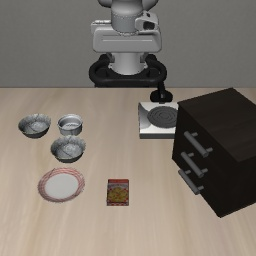

In [3]:
import json
from pathlib import Path
from PIL import Image
from IPython.display import display
sample = json.loads(Path('/content/openvla_base_one_scene/sample.json').read_text())
print('Instruction:', sample['instruction'])
print('Demonstration action (raw robot values):', sample['demonstration_action_raw'])
display(Image.open(sample['image_path']))


In [5]:
from pathlib import Path
import base64; Path('/content/base_openvla_one_scene.py').write_bytes(base64.b64decode('IiIiUnVuIG9uZSBPcGVuVkxBLTdCIHByZWRpY3Rpb247IHJlcG9ydCBub3JtYWxpemVkIGFjdGlvbnMgb25seS4KClRoaXMgc2NyaXB0IGRlbGliZXJhdGVseSBkb2VzIG5vdCBhcHBseSBhbm90aGVyIGRhdGFzZXQncyBhY3Rpb24gc2NhbGUgdG8gTElCRVJPLgpJdCBkb2VzIG5vdCBtb3ZlIGEgcm9ib3Qgb3IgbWVhc3VyZSB0YXNrIHN1Y2Nlc3MuCiIiIgoKaW1wb3J0IGFyZ3BhcnNlCmltcG9ydCBqc29uCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAoKaW1wb3J0IG51bXB5IGFzIG5wCmltcG9ydCB0b3JjaApmcm9tIFBJTCBpbXBvcnQgSW1hZ2UKZnJvbSB0cmFuc2Zvcm1lcnMgaW1wb3J0IEF1dG9Nb2RlbEZvclZpc2lvbjJTZXEsIEF1dG9Qcm9jZXNzb3IKCgpkZWYgcHJlZGljdChpbWFnZV9wYXRoOiBQYXRoLCBpbnN0cnVjdGlvbjogc3RyKSAtPiBkaWN0OgogICAgbW9kZWxfaWQgPSAib3BlbnZsYS9vcGVudmxhLTdiIgogICAgcHJvY2Vzc29yID0gQXV0b1Byb2Nlc3Nvci5mcm9tX3ByZXRyYWluZWQobW9kZWxfaWQsIHRydXN0X3JlbW90ZV9jb2RlPVRydWUpCiAgICBtb2RlbCA9IEF1dG9Nb2RlbEZvclZpc2lvbjJTZXEuZnJvbV9wcmV0cmFpbmVkKAogICAgICAgIG1vZGVsX2lkLAogICAgICAgIHRvcmNoX2R0eXBlPXRvcmNoLmJmbG9hdDE2LAogICAgICAgIGxvd19jcHVfbWVtX3VzYWdlPVRydWUsCiAgICAgICAgdHJ1c3RfcmVtb3RlX2NvZGU9VHJ1ZSwKICAgICkudG8oImN1ZGE6MCIpCiAgICBtb2RlbC5ldmFsKCkKCiAgICBpbWFnZSA9IEltYWdlLm9wZW4oaW1hZ2VfcGF0aCkuY29udmVydCgiUkdCIikKICAgIHByb21wdCA9IGYiSW46IFdoYXQgYWN0aW9uIHNob3VsZCB0aGUgcm9ib3QgdGFrZSB0byB7aW5zdHJ1Y3Rpb259P1xuT3V0OiIKICAgIGlucHV0cyA9IHByb2Nlc3Nvcihwcm9tcHQsIGltYWdlKS50bygiY3VkYTowIiwgZHR5cGU9dG9yY2guYmZsb2F0MTYpCiAgICAjIE1hdGNoIHRoZSBlbXB0eSB0b2tlbiBpbnNlcnRpb24gaW4gT3BlblZMQSdzIHByZWRpY3RfYWN0aW9uKCkuCiAgICBpZiBpbnB1dHNbImlucHV0X2lkcyJdWzAsIC0xXS5pdGVtKCkgIT0gMjk4NzE6CiAgICAgICAgZW1wdHkgPSB0b3JjaC50ZW5zb3IoW1syOTg3MV1dLCBkZXZpY2U9ImN1ZGE6MCIpCiAgICAgICAgaW5wdXRzWyJpbnB1dF9pZHMiXSA9IHRvcmNoLmNhdCgoaW5wdXRzWyJpbnB1dF9pZHMiXSwgZW1wdHkpLCBkaW09MSkKICAgICAgICBpZiAiYXR0ZW50aW9uX21hc2siIGluIGlucHV0czoKICAgICAgICAgICAgaW5wdXRzWyJhdHRlbnRpb25fbWFzayJdID0gdG9yY2guY2F0KAogICAgICAgICAgICAgICAgKGlucHV0c1siYXR0ZW50aW9uX21hc2siXSwgdG9yY2gub25lc19saWtlKGVtcHR5KSksIGRpbT0xCiAgICAgICAgICAgICkKCiAgICB3aXRoIHRvcmNoLmluZmVyZW5jZV9tb2RlKCk6CiAgICAgICAgZ2VuZXJhdGVkID0gbW9kZWwuZ2VuZXJhdGUoKippbnB1dHMsIG1heF9uZXdfdG9rZW5zPTcsIGRvX3NhbXBsZT1GYWxzZSkKCiAgICBpZHMgPSBnZW5lcmF0ZWRbMCwgLTc6XS5jcHUoKS5udW1weSgpCiAgICBmaXJzdF92YWxpZF9pZCA9IG1vZGVsLnZvY2FiX3NpemUgLSAobGVuKG1vZGVsLmJpbl9jZW50ZXJzKSkKICAgIGxhc3RfdmFsaWRfaWQgPSBtb2RlbC52b2NhYl9zaXplIC0gMQogICAgaW5fbm9taW5hbF9yYW5nZSA9IChpZHMgPj0gZmlyc3RfdmFsaWRfaWQpICYgKGlkcyA8PSBsYXN0X3ZhbGlkX2lkKQogICAgIyBPcGVuVkxBJ3Mgb3duIHByZWRpY3RfYWN0aW9uKCkgY2xpcHMgdGhlIGRlY29kZWQgYmluIGluZGV4IHRvIHRoZQogICAgIyBhdmFpbGFibGUgY2VudGVycy4gUHJlc2VydmUgdGhhdCBiZWhhdmlvciBhbmQgcmVwb3J0IGFueSBjbGlwcGVkIHRva2VuLgogICAgaW5kaWNlcyA9IG5wLmNsaXAobW9kZWwudm9jYWJfc2l6ZSAtIGlkcyAtIDEsIDAsIGxlbihtb2RlbC5iaW5fY2VudGVycykgLSAxKQogICAgYWN0aW9ucyA9IG1vZGVsLmJpbl9jZW50ZXJzW2luZGljZXNdCiAgICByZXN1bHQgPSB7CiAgICAgICAgIm1vZGVsIjogbW9kZWxfaWQsCiAgICAgICAgImltYWdlIjogc3RyKGltYWdlX3BhdGgpLAogICAgICAgICJpbnN0cnVjdGlvbiI6IGluc3RydWN0aW9uLAogICAgICAgICJhY3Rpb25fdG9rZW5faWRzIjogaWRzLnRvbGlzdCgpLAogICAgICAgICJhbGxfc2V2ZW5fdG9rZW5zX2luX25vbWluYWxfcmFuZ2UiOiBib29sKGluX25vbWluYWxfcmFuZ2UuYWxsKCkpLAogICAgICAgICJ0b2tlbnNfY2xpcHBlZF90b19hY3Rpb25fYmlucyI6IGludCgofmluX25vbWluYWxfcmFuZ2UpLnN1bSgpKSwKICAgICAgICAibm9ybWFsaXplZF9hY3Rpb24iOiBhY3Rpb25zLnRvbGlzdCgpLAogICAgICAgICJub3JtYWxpemVkX2FjdGlvbl9zaGFwZSI6IFsxLCBpbnQoYWN0aW9ucy5zaGFwZVswXSldLAogICAgICAgICJhbGxfdmFsdWVzX2Zpbml0ZSI6IGJvb2wobnAuaXNmaW5pdGUoYWN0aW9ucykuYWxsKCkpLAogICAgICAgICJncHVfcGVha19naWIiOiByb3VuZCh0b3JjaC5jdWRhLm1heF9tZW1vcnlfYWxsb2NhdGVkKCkgLyAxMDI0KiozLCAyKSwKICAgIH0KICAgIHJldHVybiByZXN1bHQKCgpkZWYgbWFpbigpIC0+IE5vbmU6CiAgICBwYXJzZXIgPSBhcmdwYXJzZS5Bcmd1bWVudFBhcnNlcigpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLWltYWdlIiwgdHlwZT1QYXRoLCByZXF1aXJlZD1UcnVlKQogICAgcGFyc2VyLmFkZF9hcmd1bWVudCgiLS1pbnN0cnVjdGlvbiIsIHJlcXVpcmVkPVRydWUpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLW91dHB1dCIsIHR5cGU9UGF0aCwgZGVmYXVsdD1QYXRoKCJiYXNlX29wZW52bGFfcmVzdWx0Lmpzb24iKSkKICAgIGFyZ3MgPSBwYXJzZXIucGFyc2VfYXJncygpCiAgICByZXN1bHQgPSBwcmVkaWN0KGFyZ3MuaW1hZ2UsIGFyZ3MuaW5zdHJ1Y3Rpb24pCiAgICBhcmdzLm91dHB1dC53cml0ZV90ZXh0KGpzb24uZHVtcHMocmVzdWx0LCBpbmRlbnQ9MiksIGVuY29kaW5nPSJ1dGYtOCIpCiAgICBwcmludChqc29uLmR1bXBzKHJlc3VsdCwgaW5kZW50PTIpKQoKCmlmIF9fbmFtZV9fID09ICJfX21haW5fXyI6CiAgICBtYWluKCkK'))
result = subprocess.run([str(venv / 'bin/python'), '/content/base_openvla_one_scene.py', '--image', sample['image_path'], '--instruction', sample['instruction'], '--output', '/content/openvla_base_one_scene/prediction.json'], capture_output=True, text=True)
print(result.stdout[-3000:])
print(result.stderr[-1000:])
result.check_returncode()


{
  "model": "openvla/openvla-7b",
  "image": "/content/openvla_base_one_scene/libero_target_scene.png",
  "instruction": "pick up the black bowl between the plate and the ramekin and place it on the plate",
  "action_token_ids": [
    31891,
    31877,
    31902,
    31856,
    31872,
    31868,
    31744
  ],
  "all_seven_tokens_in_nominal_range": false,
  "tokens_clipped_to_action_bins": 1,
  "normalized_action": [
    -0.14901960784313728,
    -0.03921568627450983,
    -0.23529411764705888,
    0.12549019607843137,
    0.0,
    0.03137254901960773,
    0.996078431372549
  ],
  "normalized_action_shape": [
    1,
    7
  ],
  "all_values_finite": true,
  "gpu_peak_gib": 14.42
}

new download, use `force_download=True`.
  warnings.warn(
/content/openvla310/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use

In [6]:
import json
from pathlib import Path
prediction = json.loads(Path('/content/openvla_base_one_scene/prediction.json').read_text())
for key in ['model', 'normalized_action', 'normalized_action_shape', 'all_values_finite', 'tokens_clipped_to_action_bins', 'gpu_peak_gib']:
    print(f'{key}: {prediction[key]}')

model: openvla/openvla-7b
normalized_action: [-0.14901960784313728, -0.03921568627450983, -0.23529411764705888, 0.12549019607843137, 0.0, 0.03137254901960773, 0.996078431372549]
normalized_action_shape: [1, 7]
all_values_finite: True
tokens_clipped_to_action_bins: 1
gpu_peak_gib: 14.42


In [7]:
# Apply the existing training-only q01/q99 statistics; do not use validation data.
import base64, subprocess
from pathlib import Path
Path('/content/convert_openvla_action.py').write_bytes(base64.b64decode('IiIiQ29udmVydCBvbmUgT3BlblZMQSBwcmVkaWN0aW9uIHRvIHRoZSBwcmlvciBMSUJFUk8gYm93bCBhY3Rpb24gc2NhbGUuCgpUaGUgc3RhdGlzdGljcyBjb21lIGZyb20gMjAgdHJhaW5pbmcgZGVtb25zdHJhdGlvbnMsIG5ldmVyIHZhbGlkYXRpb24gZGF0YS4KVGhpcyBvbmx5IGNvbnZlcnRzIG51bWJlcnM7IGl0IGRvZXMgbm90IGV4ZWN1dGUgYW4gYWN0aW9uIGluIE11Sm9Dby4KIiIiCgppbXBvcnQgYXJncGFyc2UKaW1wb3J0IGpzb24KZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCgppbXBvcnQgbnVtcHkgYXMgbnAKCgpkZWYgY29udmVydChwcmVkaWN0aW9uOiBkaWN0LCBzdGF0czogZGljdCkgLT4gZGljdDoKICAgIG5vcm1hbGl6ZWQgPSBucC5hc2FycmF5KHByZWRpY3Rpb25bIm5vcm1hbGl6ZWRfYWN0aW9uIl0sIGR0eXBlPW5wLmZsb2F0NjQpCiAgICBsb3cgPSBucC5hc2FycmF5KHN0YXRzWyJxMDEiXSwgZHR5cGU9bnAuZmxvYXQ2NCkKICAgIGhpZ2ggPSBucC5hc2FycmF5KHN0YXRzWyJxOTkiXSwgZHR5cGU9bnAuZmxvYXQ2NCkKICAgIGlmIG5vcm1hbGl6ZWQuc2hhcGUgIT0gKDcsKSBvciBsb3cuc2hhcGUgIT0gKDcsKSBvciBoaWdoLnNoYXBlICE9ICg3LCk6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcigiRXhwZWN0ZWQgc2V2ZW4gYWN0aW9uIHZhbHVlcyBhbmQgc2V2ZW4gcTAxL3E5OSB2YWx1ZXMiKQogICAgaWYgbm90IG5wLmlzZmluaXRlKG5vcm1hbGl6ZWQpLmFsbCgpIG9yIG5vdCBucC5pc2Zpbml0ZShsb3cpLmFsbCgpIG9yIG5vdCBucC5pc2Zpbml0ZShoaWdoKS5hbGwoKToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCJBY3Rpb25zIGFuZCBzdGF0aXN0aWNzIG11c3QgY29udGFpbiBmaW5pdGUgbnVtYmVycyIpCiAgICBpZiBucC5hbnkoaGlnaFs6Nl0gPD0gbG93Wzo2XSk6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcigiRWFjaCBhcm0tYWN0aW9uIHE5OSBtdXN0IGV4Y2VlZCBxMDEiKQoKICAgICMgT3BlblZMQSBub3JtYWxpemVzIHRoZSBhcm0gY29vcmRpbmF0ZXMgdG8gWy0xLCAxXS4gVGhlIGdyaXBwZXIgdXNlcyBhCiAgICAjIHNlcGFyYXRlIDA9Y2xvc2UsIDE9b3BlbiBjb252ZW50aW9uIGluIHRoZSBMSUJFUk8gZGF0YSB3cmFwcGVyLgogICAgYWN0aW9uID0gbnAuZW1wdHkoNywgZHR5cGU9bnAuZmxvYXQ2NCkKICAgIGFjdGlvbls6Nl0gPSBsb3dbOjZdICsgKG5vcm1hbGl6ZWRbOjZdICsgMS4wKSAqIChoaWdoWzo2XSAtIGxvd1s6Nl0pIC8gMi4wCiAgICBhY3Rpb25bNl0gPSBub3JtYWxpemVkWzZdCgogICAgIyBNYXRjaCBPcGVuVkxBJ3MgTElCRVJPIGV2YWx1YXRpb246IFswLDFdIC0+IFstMSwrMV0sIGJpbmFyaXplLAogICAgIyB0aGVuIGZsaXAgc2lnbiBzbyBMSUJFUk8gcmVjZWl2ZXMgLTE9b3BlbiwgKzE9Y2xvc2UuCiAgICBjb250cm9sbGVyID0gYWN0aW9uLmNvcHkoKQogICAgY29udHJvbGxlcls2XSA9IC1ucC5zaWduKDIuMCAqIGFjdGlvbls2XSAtIDEuMCkKICAgIHJlc3VsdCA9IHsKICAgICAgICAibW9kZWwiOiBwcmVkaWN0aW9uWyJtb2RlbCJdLAogICAgICAgICJzdGF0aXN0aWNzX3NvdXJjZSI6ICJleGlzdGluZyB0cmFpbjIwIGFjdGlvbl9zdGF0cy5qc29uOyAyMCBlcGlzb2RlcywgMTkyOCBmcmFtZXMiLAogICAgICAgICJ2YWxpZGF0aW9uX3VzZWRfZm9yX3N0YXRpc3RpY3MiOiBGYWxzZSwKICAgICAgICAibm9ybWFsaXplZF9hY3Rpb24iOiBub3JtYWxpemVkLnRvbGlzdCgpLAogICAgICAgICJhY3Rpb25fb25fdHJhaW4yMF9zY2FsZSI6IGFjdGlvbi50b2xpc3QoKSwKICAgICAgICAibGliZXJvX2NvbnRyb2xsZXJfYWN0aW9uX2NhbmRpZGF0ZSI6IGNvbnRyb2xsZXIudG9saXN0KCksCiAgICAgICAgInNoYXBlIjogWzEsIDddLAogICAgICAgICJhbGxfdmFsdWVzX2Zpbml0ZSI6IGJvb2wobnAuaXNmaW5pdGUoY29udHJvbGxlcikuYWxsKCkpLAogICAgICAgICJncmlwcGVyX2FjdGlvbl9pbl8wXzFfcmFuZ2UiOiBib29sKDAuMCA8PSBhY3Rpb25bNl0gPD0gMS4wKSwKICAgICAgICAiY29udHJvbGxlcl9leGVjdXRlZCI6IEZhbHNlLAogICAgfQogICAgcmV0dXJuIHJlc3VsdAoKCmRlZiBtYWluKCkgLT4gTm9uZToKICAgIHBhcnNlciA9IGFyZ3BhcnNlLkFyZ3VtZW50UGFyc2VyKCkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tcHJlZGljdGlvbiIsIHR5cGU9UGF0aCwgcmVxdWlyZWQ9VHJ1ZSkKICAgIHBhcnNlci5hZGRfYXJndW1lbnQoIi0tc3RhdHMiLCB0eXBlPVBhdGgsIHJlcXVpcmVkPVRydWUpCiAgICBwYXJzZXIuYWRkX2FyZ3VtZW50KCItLW91dHB1dCIsIHR5cGU9UGF0aCwgcmVxdWlyZWQ9VHJ1ZSkKICAgIGFyZ3MgPSBwYXJzZXIucGFyc2VfYXJncygpCiAgICBwcmVkaWN0aW9uID0ganNvbi5sb2FkcyhhcmdzLnByZWRpY3Rpb24ucmVhZF90ZXh0KGVuY29kaW5nPSJ1dGYtOCIpKQogICAgc3RhdHMgPSBqc29uLmxvYWRzKGFyZ3Muc3RhdHMucmVhZF90ZXh0KGVuY29kaW5nPSJ1dGYtOCIpKQogICAgcmVzdWx0ID0gY29udmVydChwcmVkaWN0aW9uLCBzdGF0cykKICAgIGFyZ3Mub3V0cHV0LndyaXRlX3RleHQoanNvbi5kdW1wcyhyZXN1bHQsIGluZGVudD0yLCBhbGxvd19uYW49RmFsc2UpLCBlbmNvZGluZz0idXRmLTgiKQogICAgcHJpbnQoanNvbi5kdW1wcyhyZXN1bHQsIGluZGVudD0yLCBhbGxvd19uYW49RmFsc2UpKQoKCmlmIF9fbmFtZV9fID09ICJfX21haW5fXyI6CiAgICBtYWluKCkK'))
Path('/content/openvla_base_one_scene/train20_action_stats.json').write_bytes(base64.b64decode('ewogICJzb3VyY2UiOiAidHJhaW5pbmcgZXBpc29kZXMgb25seSIsCiAgImVwaXNvZGVzIjogMjAsCiAgImZyYW1lcyI6IDE5MjgsCiAgIm1lYW4iOiBbCiAgICAwLjE4ODk3OTQxNzA4NTY0NzU4LAogICAgMC4xMjgyODEwNDE5Nzk3ODk3MywKICAgIC0wLjE4MzUxOTY5MTIyODg2NjU4LAogICAgMC4wMDgwMDQwNDA0NTczMDgyOTIsCiAgICAtMC4wMDk0OTcyNTUwODY4OTg4MDQsCiAgICAtMC4wMjg4NDYzMzY1Mjg2NTg4NjcsCiAgICAwLjUxNTU2MDE1MDE0NjQ4NDQKICBdLAogICJzdGQiOiBbCiAgICAwLjUxNTg0NjI1MjQ0MTQwNjIsCiAgICAwLjIwNjI4NDg2NTczNjk2MTM2LAogICAgMC42MTM4NTY5NzEyNjM4ODU1LAogICAgMC4wNDQwMDY2NzU0ODE3OTYyNjUsCiAgICAwLjA3NTcwNDIzOTMwODgzNDA4LAogICAgMC4wNjE0NjMxNzM0Nzg4NDE3OCwKICAgIDAuNDk5NzU4OTU4ODE2NTI4MwogIF0sCiAgIm1pbiI6IFsKICAgIC0wLjkzNzUsCiAgICAtMC4zOTEwNzE0Mzg3ODkzNjc3LAogICAgLTAuOTM3NSwKICAgIC0wLjE1MjE0Mjg1MjU0NDc4NDU1LAogICAgLTAuMjQ5NjQyODYzODY5NjY3MDUsCiAgICAtMC4yNDEwNzE0MzI4Mjg5MDMyLAogICAgMC4wCiAgXSwKICAibWF4IjogWwogICAgMC45Mzc1LAogICAgMC42ODAzNTcxNTgxODQwNTE1LAogICAgMC45Mzc1LAogICAgMC4xOTcxNDI4NTQzMzI5MjM5LAogICAgMC4yMDg5Mjg1NzAxNTEzMjkwNCwKICAgIDAuMTkyODU3MTQ2MjYzMTIyNTYsCiAgICAxLjAKICBdLAogICJxMDEiOiBbCiAgICAtMC44OTY1OTgxODgyODEwNTkzLAogICAgLTAuMjg5Nzk0NjQ4Mjg5NjgwNSwKICAgIC0wLjkzNzUsCiAgICAtMC4wOTgyODIxNDA4NjU5MjE5OCwKICAgIC0wLjIwMzU3MTQyMzg4ODIwNjQ4LAogICAgLTAuMTg3MjEwNzE1NzExMTE2OCwKICAgIDAuMAogIF0sCiAgInE5OSI6IFsKICAgIDAuOTM3NSwKICAgIDAuNjI4NzQxMDUzOTM4ODY1NywKICAgIDAuOTM0ODIxNDI2ODY4NDM4NywKICAgIDAuMTMyNTY3ODU5NTkwMDUzNTcsCiAgICAwLjE2NzYzNTcxODczMzA3MjMxLAogICAgMC4xMTg1NTM1Njk4Mzg0MDQ3NiwKICAgIDEuMAogIF0KfQo='))
result = subprocess.run([str(venv / 'bin/python'), '/content/convert_openvla_action.py',
    '--prediction', '/content/openvla_base_one_scene/prediction.json',
    '--stats', '/content/openvla_base_one_scene/train20_action_stats.json',
    '--output', '/content/openvla_base_one_scene/converted_action.json'], capture_output=True, text=True)
print(result.stdout)
print(result.stderr[-500:])
result.check_returncode()


{
  "model": "openvla/openvla-7b",
  "statistics_source": "existing train20 action_stats.json; 20 episodes, 1928 frames",
  "validation_used_for_statistics": false,
  "normalized_action": [
    -0.14901960784313728,
    -0.03921568627450983,
    -0.23529411764705888,
    0.12549019607843137,
    0.0,
    0.03137254901960773,
    0.996078431372549
  ],
  "action_on_train20_scale": [
    -0.1162073905222557,
    0.15146269885932695,
    -0.22161239560912638,
    0.03162756527302897,
    -0.017967852577567084,
    -0.02953227041793216,
    0.996078431372549
  ],
  "libero_controller_action_candidate": [
    -0.1162073905222557,
    0.15146269885932695,
    -0.22161239560912638,
    0.03162756527302897,
    -0.017967852577567084,
    -0.02953227041793216,
    -1.0
  ],
  "shape": [
    1,
    7
  ],
  "all_values_finite": true,
  "gripper_action_in_0_1_range": true,
  "controller_executed": false
}




In [8]:
import json
from pathlib import Path
root = Path('/content/openvla_base_one_scene')
converted = json.loads((root / 'converted_action.json').read_text())
demo = json.loads((root / 'sample.json').read_text())
command = converted['libero_controller_action_candidate']
print('Arm command (6):', [round(x, 4) for x in command[:6]])
print('Gripper command (1):', command[6], '(demo first step:', demo['demonstration_action_raw'][6], ')')
print('Shape:', converted['shape'], 'Finite:', converted['all_values_finite'])
print('Validation used for scale:', converted['validation_used_for_statistics'])
print('Executed in simulator:', converted['controller_executed'])

Arm command (6): [-0.1162, 0.1515, -0.2216, 0.0316, -0.018, -0.0295]
Gripper command (1): -1.0 (demo first step: -1.0 )
Shape: [1, 7] Finite: True
Validation used for scale: False
Executed in simulator: False
